In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv


# IsolationForest em fraude de cartão de crédito (dados reais anonimizados)

Aplico aqui o mesmo método do projeto [mlops-anomalias](https://github.com/DevDaih/mlops-anomalias)
(IsolationForest, rótulos usados só na avaliação) a um dataset real. O modelo do projeto, treinado em
dados **sintéticos**, está em https://huggingface.co/DevDaih/mlops-anomalias-isolation-forest.

**Atenção:** os resultados abaixo são deste dataset e não são comparáveis com os do projeto sintético.

**Fonte:** [Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud),
Machine Learning Group - ULB, em colaboração com a Worldline. Transações de cartão de setembro de
2013, 284.807 registros, 492 fraudes (0,172%); `V1` a `V28` são componentes de PCA.
**Licença:** Open Database License (ODbL) para o banco de dados e Database Contents License (DbCL 1.0)
para o conteúdo, conforme a página do dataset no Kaggle. O notebook não redistribui os dados.
**Citação sugerida pelos autores:** Andrea Dal Pozzolo, Olivier Caelen, Reid A. Johnson e Gianluca
Bontempi. *Calibrating Probability with Undersampling for Unbalanced Classification.* Symposium on
Computational Intelligence and Data Mining (CIDM), IEEE, 2015.

In [2]:
import glob
import pandas as pd

caminho = glob.glob("/kaggle/input/**/creditcard.csv", recursive=True)[0]
print(caminho)
df = pd.read_csv(caminho)
print(df.shape)
print("Proporção de fraudes:", round(df["Class"].mean(), 5))

/kaggle/input/datasets/mlg-ulb/creditcardfraud/creditcard.csv
(284807, 31)
Proporção de fraudes: 0.00173


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
X = df.drop(columns="Class")
y = df["Class"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, stratify=y, random_state=SEED
)

# V1..V28 já vêm de PCA; padroniza só Time e Amount (ajustado no treino)
scaler = StandardScaler().fit(X_train[["Time", "Amount"]])
for part in (X_train, X_test):
    part[["Time", "Amount"]] = scaler.transform(part[["Time", "Amount"]])
print(len(X_train), len(X_test), y_test.sum(), "fraudes no teste")

199364 85443 148 fraudes no teste


In [4]:
from sklearn.ensemble import IsolationForest

contamination = float(y_train.mean())  # conhecida aqui; em produção não seria
model = IsolationForest(
    n_estimators=200, contamination=contamination, random_state=SEED, n_jobs=-1
).fit(X_train)  # sem y_train
print("contamination:", round(contamination, 5))

contamination: 0.00173


In [5]:
from sklearn.metrics import (precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score)

raw = model.score_samples(X_test)
score = -raw                         # maior = mais anômalo (mesma convenção do projeto)
pred = ((raw - model.offset_) < 0).astype(int)

real = {
    "precisão": precision_score(y_test, pred, zero_division=0),
    "recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, score),
    "PR-AUC": average_precision_score(y_test, score),
}
baseline = float(y_test.mean())
for k, v in real.items():
    print(f"{k}: {v:.4f}")
print(f"PR-AUC de um modelo aleatório (proporção de fraudes): {baseline:.4f}")

precisão: 0.2465
recall: 0.2365
F1: 0.2414
ROC-AUC: 0.9460
PR-AUC: 0.1374
PR-AUC de um modelo aleatório (proporção de fraudes): 0.0017


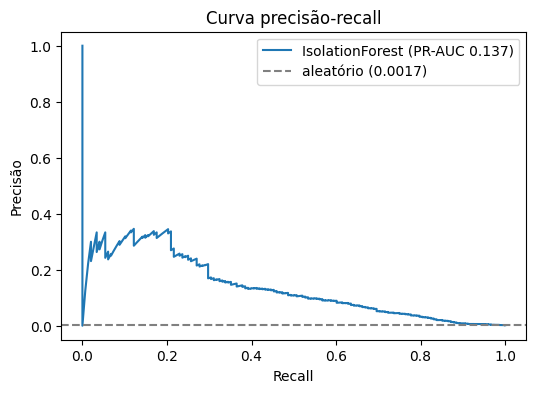

In [6]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve

p, r, _ = precision_recall_curve(y_test, score)
plt.figure(figsize=(6, 4))
plt.plot(r, p, label=f"IsolationForest (PR-AUC {real['PR-AUC']:.3f})")
plt.axhline(baseline, ls="--", color="gray", label=f"aleatório ({baseline:.4f})")
plt.xlabel("Recall"); plt.ylabel("Precisão"); plt.title("Curva precisão-recall")
plt.legend(); plt.show()

In [7]:
# Valores do README do projeto (seção Resultados, modelo v1, dados SINTÉTICOS).
sintetico = {"precisão": 0.935, "recall": 0.960, "F1": 0.947, "ROC-AUC": 0.9996}

tabela = pd.DataFrame({
    "sintético (projeto)": {k: sintetico.get(k) for k in real},
    "real (este notebook)": real,
}).round(4)
tabela = tabela.astype(object)
tabela.loc["PR-AUC", "sintético (projeto)"] = "não medido"
tabela

,sintético (projeto),real (este notebook)
precisão,0.935,0.2465
recall,0.96,0.2365
F1,0.947,0.2414
ROC-AUC,0.9996,0.946
PR-AUC,não medido,0.1374



## Comparação com o projeto sintético

| Métrica | Sintético (projeto) | Real (este notebook) |
|---|---|---|
| Precisão | 0,935 | 0,2465 |
| Recall | 0,960 | 0,2365 |
| F1 | 0,947 | 0,2414 |
| ROC-AUC | 0,9996 | 0,9460 |
| PR-AUC | não medido | 0,1374 |

Os dois cenários são problemas diferentes e a tabela não mede qual modelo é melhor, só mostra
o que o mesmo método faz em cada um. No projeto sintético, as anomalias são injetadas bem
afastadas dos dados normais e o IsolationForest as separa quase perfeitamente (F1 0,947).
Nas fraudes reais, o mesmo método acerta cerca de 1 em cada 4 alertas (precisão 0,2465) e
encontra cerca de 24% das fraudes (recall 0,2365).

O ROC-AUC de 0,9460 parece bom, mas engana: com apenas 0,172% de fraudes, ele é pouco
sensível ao volume de falsos positivos. A PR-AUC, a métrica que a página do dataset recomenda
(AUPRC), é 0,1374, cerca de 80 vezes a proporção de fraudes (0,17%), o que mostra que o
modelo ordena as transações melhor que o acaso, mas está longe de ser um detector utilizável
sozinho. Por isso o ROC-AUC de 0,9996 do projeto sintético não deve ser lido como desempenho
esperado em dados reais.

## Limitações

- Uma única execução, sem validação cruzada e sem ajuste de hiperparâmetros.
- `contamination` foi definida com a proporção real de fraudes do treino; em produção ela não
  seria conhecida.
- `V1` a `V28` são componentes de PCA (anonimizadas): não dá para interpretar as features.
- Dados de apenas 2 dias de 2013, de titulares europeus.
- Pela recomendação da página do dataset, a métrica principal é a PR-AUC; a acurácia não é
  informativa com 0,172% de fraudes.